In [1]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
import class_EDDIES as ed
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from pyproj import Geod
import numpy as np
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch

In [2]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return hours, minutes

def get_time_mask(month, day,new_adcp, t_adcp, dm = True):
    mask = (t_adcp.dt.month == month) & (t_adcp.dt.day == day)
    new_adcp = new_adcp.isel(time=mask)
    if dm:
        depth_mask = (new_adcp.depth < -50) & (new_adcp.depth > -100)
        new_adcp = new_adcp.isel(depth=depth_mask)
    return new_adcp

def get_depth_mask(new_adcp):
    depth_mask = (new_adcp.depth < -50) & (new_adcp.depth > -100)
    new_adcp = new_adcp.isel(depth=depth_mask)
    return new_adcp

geod = Geod(ellps="WGS84")

def along_track_distance(lon, lat):
    """
    Returns cumulative distance in meters along a track.
    """
    lon = np.asarray(lon)
    lat = np.asarray(lat)

    # distance between consecutive points
    _, _, dist = geod.inv(lon[:-1], lat[:-1], lon[1:], lat[1:])

    # cumulative sum (prepend 0 for starting point)
    return np.concatenate([[0], np.cumsum(dist)])


def load_eddies(dir_eddies):
    """Load cyclonic and anticyclonic eddy shapefiles."""

    anti = {}
    cyc = {}

    for fname in os.listdir(dir_eddies):

        if "anti" in fname:
            target = anti
        else:
            target = cyc

        if "maxspeed" in fname:
            target["maxspeed"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "outcontour" in fname:
            target["outcontour"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "centers" in fname:
            target["centers"] = gpd.read_file(os.path.join(dir_eddies, fname))

    return anti, cyc

def load_satellite(adt_path):

    # ds = xr.open_dataset(adt_daily_dir + file_adt)
    ds = xr.open_dataset(adt_path)
    if "time" in ds:
        ds = ds.drop_vars("time")
    ds.close()
    return {
        "dataset": ds,
        "lon": ds.longitude,
        "lat": ds.latitude,
        "adt": ds.adt,
        "ugos": np.squeeze(ds.ugos),
        "vgos": np.squeeze(ds.vgos)
    }


def average_adcp_velocity(curr_day):

    u = curr_day.uvel_adcp.values
    v = curr_day.vvel_adcp.values

    mask = (
        ~np.isnan(u).any(axis=1)
        &
        ~np.isnan(v).any(axis=1)
    )

    u_mean = np.full(u.shape[0], np.nan)
    v_mean = np.full(v.shape[0], np.nan)

    u_mean[mask] = u[mask].mean(axis=1)
    v_mean[mask] = v[mask].mean(axis=1)

    return u_mean, v_mean

def velocity_magnitude(u, v):
    return np.sqrt(u**2 + v**2)

def interpolate_satellite(curr_day, ugos, vgos):

    u = ugos.interp(
        longitude=curr_day.lon_adcp,
        latitude=curr_day.lat_adcp,
        method="nearest"
    )

    v = vgos.interp(
        longitude=curr_day.lon_adcp,
        latitude=curr_day.lat_adcp,
        method="nearest"
    )

    return u, v

def plot_eddies(ax, eddies, color, crs):

    ms = eddies["maxspeed"]
    oc = eddies["outcontour"]
    cent = eddies["centers"]

    for i in range(len(cent)):

        if ms.geometry[i] is None:
            continue

        x, y = ms.geometry[i].exterior.xy
        ax.plot(x, y, color=color, transform=crs, zorder=20)

        x, y = oc.geometry[i].exterior.xy
        ax.plot(
            x,
            y,
            "--",
            color=color,
            transform=crs,
            zorder=20
        )

        ax.scatter(
            cent.geometry[i].x,
            cent.geometry[i].y,
            s=10,
            color=color,
            transform=crs,
            zorder=20
        )

def plot_along_track(
    x_dist,
    adcp_mag,
    sat_mag,
    month,
    day
):

    plt.figure()

    plt.plot(
        -x_dist/1000,
        adcp_mag,
        color="blueviolet",
        label="ADCP"
    )

    plt.plot(
        -x_dist/1000,
        sat_mag,
        color="orange",
        label="Satellite"
    )

    plt.legend()
    plt.xlabel("Along-track distance (km)")
    plt.ylabel("Velocity (m/s)")
    plt.title(f"{month}-{day}")

def plot_adcp_section(curr_day, adcp_mag, x_dist, title, vmin, vmax):

    fig, ax = plt.subplots(figsize=(9,4))

    c = ax.contourf(
        x_dist,
        curr_day.depth.values,
        adcp_mag.T,
        levels=np.arange(vmin, vmax, 0.01),
    )
    ax.invert_xaxis()
    cbar = fig.colorbar(c, ax=ax)
    cbar.set_label("Velocity [m/s]")
    ax.set_xlabel("Distance [km]")
    ax.set_ylabel("Depth [m]")
    ax.set_title(f"{title} ADCP velocity magnitude")

    return fig, ax
def setup_map(ax, extent, title, crs, ft):
    """Apply common formatting to Cartopy maps."""

    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.set_title(title)

    ax.add_feature(
        cfeature.LAND,
        linewidth=0.5,
        edgecolor="black",
        facecolor="gray",
        zorder=4
    )

    ax.coastlines(
        resolution="10m",
        color="k",
        zorder=5
    )

    grid = ax.gridlines(
        draw_labels=True,
        linewidth=1,
        color="black",
        alpha=0.2,
        linestyle="--",
        zorder=6
    )

    grid.top_labels = False
    grid.right_labels = False
    grid.left_labels = True
    grid.xlabel_style = {"size": ft}
    grid.ylabel_style = {"size": ft}

def plot_adcp_satellite_map(
    curr_day,
    sat,
    sat_mag,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    longs_bato,
    lat_bato,
    x_dist,
):
    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        sat_mag,
        levels=np.arange(0, 2.5, 0.1),
        cmap="Spectral_r",
        transform=crs,
    )

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=1,
        color="black",
        transform=crs,
        zorder=15,
    )

    step = 50

    # =========================
    # ADCP vectors
    # =========================
    q_adcp = ax.quiver(
        curr_day.lon_adcp.values[::step],
        curr_day.lat_adcp.values[::step],
        u_adcp[::step],
        v_adcp[::step],
        transform=crs,
        scale=3,
        width=0.005,
        color="blueviolet",
        zorder=100,
    )

    # =========================
    # Satellite vectors
    # =========================
    q_sat = ax.quiver(
        curr_day.lon_adcp.values[::step],
        curr_day.lat_adcp.values[::step],
        ugos_track.values[::step],
        vgos_track.values[::step],
        transform=crs,
        scale=3,
        width=0.005,
        color="orange",
        zorder=100,
    )

    # =========================
    # 🔥 DISTANCE LABELS (NEW)
    # =========================
    target_dists = np.arange(50, np.nanmax(x_dist)/1000, 50)  # km

    x_km = x_dist / 1000
    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    for d in target_dists:
        idx = np.argmin(np.abs(x_km - d))

        ax.text(
            lon[idx],
            lat[idx],
            f"{int(d)} km",
            transform=crs,
            fontsize=3,
            color="black",
            ha="left",
            va="bottom",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.2,
                alpha=0.8,
            ),
            zorder=120,
        )

    # =========================
    # Eddies
    # =========================
    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    # =========================
    # Colorbar
    # =========================
    cb = fig.colorbar(c, ax=ax, shrink=0.6)
    cb.set_label("Geostrophic Velocity [m/s]")

    # =========================
    # Reference arrow
    # =========================
    ax.quiverkey(
        q_adcp,
        X=1.1,
        Y=0.9,
        U=0.2,
        label="0.2 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="black"
    )


    # =========================
    # Legend
    # =========================
    from matplotlib.lines import Line2D

    legend_handles = [
        Line2D([0], [0], color="blueviolet", lw=2, label="ADCP"),
        Line2D([0], [0], color="orange", lw=2, label="Satellite"),
    ]

    leg = ax.legend(
        handles=legend_handles,
        loc="upper right",
        fontsize="small",
        frameon=True,
    )
    leg.set_zorder(110)

    return fig, ax
# def plot_adcp_satellite_map(
#     curr_day,
#     sat,
#     sat_mag,
#     u_adcp,
#     v_adcp,
#     ugos_track,
#     vgos_track,
#     anti,
#     cyc,
#     extent,
#     title,
#     proj,
#     crs,
#     ft,
#     longs_bato,
#     lat_bato,
# ):
#     fig = plt.figure(dpi=200)
#     ax = fig.add_subplot(111, projection=proj)

#     setup_map(ax, extent, title, crs, ft)

#     c = ax.contourf(
#         sat["lon"],
#         sat["lat"],
#         sat_mag,
#         levels=np.arange(0, 2.5, 0.1),
#         cmap="Spectral_r",
#         transform=crs,
#     )

#     ax.scatter(
#         longs_bato[::50],
#         lat_bato[::50],
#         s=1,
#         color="black",
#         transform=crs,
#         zorder=15,
#     )

#     step = 50

#     # =========================
#     # ADCP vectors
#     # =========================
#     q_adcp = ax.quiver(
#         curr_day.lon_adcp.values[::step],
#         curr_day.lat_adcp.values[::step],
#         u_adcp[::step],
#         v_adcp[::step],
#         transform=crs,
#         scale=3,
#         width=0.005,
#         color="blueviolet",
#         zorder=100,
#     )

#     # =========================
#     # Satellite vectors
#     # =========================
#     q_sat = ax.quiver(
#         curr_day.lon_adcp.values[::step],
#         curr_day.lat_adcp.values[::step],
#         ugos_track.values[::step],
#         vgos_track.values[::step],
#         transform=crs,
#         scale=3,
#         width=0.005,
#         color="orange",
#         zorder=100,
#     )

#     # =========================
#     # Eddies
#     # =========================
#     plot_eddies(ax, anti, "red", crs)
#     plot_eddies(ax, cyc, "blue", crs)

#     # =========================
#     # Colorbar
#     # =========================
#     cb = fig.colorbar(c, ax=ax, shrink=0.6)
#     cb.set_label("Geostrophic Velocity [m/s]")

#     # =========================
#     # Reference arrow (0.5 m/s)
#     # =========================
#     # =========================
#     # Reference arrow (0.5 m/s)
#     # =========================
#     ax.quiverkey(
#         q_adcp,   # or q_sat
#         X=1.1,
#         Y=0.9,
#         U=0.2,
#         label="0.2 m/s",
#         fontproperties={"size": 8},
#         labelpos="E",
#         color="black")
        
#     # =========================
#     # LEGEND (manual handles)
#     # =========================
#     from matplotlib.lines import Line2D

#     legend_handles = [
#         Line2D([0], [0], color="blueviolet", lw=2, label="ADCP"),
#         Line2D([0], [0], color="orange", lw=2, label="Satellite"),
#     ]

#     leg = ax.legend(
#         handles=legend_handles,
#         loc="upper right",
#         fontsize="small",
#         frameon=True,
#     )
#     leg.set_zorder(110) 
#     return fig, ax
def plot_adt_map(
    sat,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    vmin,
    vmax,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    curr_day,
    x_dist
):

    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    bathy = ax.contour(
        lon_subset,
        lat_subset,
        depth_subset,
        colors="grey",
        linewidths=0.8,
        transform=crs,
    )

    ax.clabel(bathy, fontsize=4)

    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        sat["adt"][0],
        levels=np.arange(vmin, vmax, 0.01),
        cmap="RdBu_r",
        transform=crs,
    )

    lon2d, lat2d = np.meshgrid(
        sat["lon"].values,
        sat["lat"].values
    )

    step = 2

    Q = ax.quiver(
        lon2d[::step, ::step],
        lat2d[::step, ::step],
        sat["ugos"].values[::step, ::step],
        sat["vgos"].values[::step, ::step],
        transform=crs,
        scale=18,
    )
    target_dists = np.arange(50, np.nanmax(x_dist)/1000, 50)  # km

    x_km = x_dist / 1000
    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    for d in target_dists:
        idx = np.argmin(np.abs(x_km - d))

        ax.text(
            lon[idx],
            lat[idx],
            f"{int(d)} km",
            transform=crs,
            fontsize=3,
            color="black",
            ha="left",
            va="bottom",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.2,
                alpha=0.8,
            ),
            zorder=120,
        )

    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=0.5,
        color="green",
        transform=crs,
        zorder=90,
    )

    ax.quiverkey(
        Q,
        X=1.08,
        Y=0.92,
        U=0.5,
        label="0.5 m/s",
        labelpos="E",
    )

    cb = fig.colorbar(c, ax=ax, shrink=0.6)
    cb.set_label("ADT [m]")

    return fig, ax


def plot_alongtrack(x_dist, adcp_mag, sat_mag, title):

    fig, ax = plt.subplots(figsize=(8,4))

    ax.plot(
        -x_dist / 1000,
        adcp_mag,
        color="blueviolet",
        label="ADCP",
    )

    ax.plot(
        -x_dist / 1000,
        sat_mag,
        color="orange",
        label="Satellite",
    )

    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Velocity (m/s)")
    ax.set_title(title)
    ax.legend()

    return fig, ax

def plot_rel_vort_map(
    curr_day,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    sat,
    rel_vort,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    vmin,
    vmax,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    cbar_lab,
    deg=0.125,
    cmap="RdBu_r",
    extend=True
):

    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    bathy = ax.contour(
        lon_subset,
        lat_subset,
        depth_subset,
        colors="grey",
        linewidths=0.8,
        transform=crs,
    )

    ax.clabel(bathy, fontsize=4)
    levels = np.linspace(vmin, vmax, 51)
    if extend:
        e = 'both'
    else:
        e = 'min'
    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        rel_vort,
        levels=levels,
        cmap=cmap,
        transform=crs,
        extend=e
    )

    
    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    u = u_adcp
    v = v_adcp

    # round to nearest 0.1 degree grid
    lon_bin = np.round(lon / deg) * deg
    lat_bin = np.round(lat / deg) * deg

    # keep only unique grid points
    mask = np.ones(lon.shape, dtype=bool)

    seen = set()

    for i in range(lon.size):
        key = (lon_bin[i], lat_bin[i])
        if key in seen:
            mask[i] = False
        else:
            seen.add(key)
    q_adcp = ax.quiver(
        lon[mask],
        lat[mask],
        u[mask],
        v[mask],
        transform=crs,
        scale=8,
        width=0.005,
        color="blueviolet",
        zorder=100,
    )

    lon2d, lat2d = np.meshgrid(
        sat["lon"].values,
        sat["lat"].values
    )

    step = 2

    Q = ax.quiver(
        lon2d[::step, ::step],
        lat2d[::step, ::step],
        sat["ugos"].values[::step, ::step],
        sat["vgos"].values[::step, ::step],
        transform=crs,
        scale=18,
    )

    # =========================
    # Satellite vectors
    # =========================
    q_sat = ax.quiver(
        curr_day.lon_adcp.values[mask],
        curr_day.lat_adcp.values[mask],
        ugos_track.values[mask],
        vgos_track.values[mask],
        transform=crs,
        scale=8,
        width=0.005,
        color="orange",
        zorder=100,
    )

    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=0.5,
        color="black",
        transform=crs,
        zorder=90,
    )
    ax.quiverkey(
        q_adcp,
        X=1.1,
        Y=0.9,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="orange"
    )
    ax.quiverkey(
        q_sat,
        X=1.1,
        Y=0.86,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="blueviolet"
    )
    ax.quiverkey(
        Q,
        X=1.1,
        Y=0.94,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color = "black"
    )


    cb = fig.colorbar(c, ax=ax, shrink=0.6)

    ticks = np.arange(vmin, vmax + 0.1, 0.1)
    if "Total Strain" in title:
        ticks = np.arange(vmin, vmax, 0.1)

    cb.set_ticks(ticks)
    cb.set_label(f"{cbar_lab} [s-1]")
    return fig, ax

    
def plot_adcp_satellite_map_no_xdist(
    curr_day,
    sat,
    sat_mag,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    longs_bato,
    lat_bato,
    deg=0.2
):
    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        sat_mag,
        levels=np.arange(0, 2.5, 0.05),
        cmap="Spectral_r",
        transform=crs,
    )

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=1,
        color="black",
        transform=crs,
        zorder=15,
    )

    # =========================
    # ADCP vectors
    # =========================

    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    u = u_adcp
    v = v_adcp

    # round to nearest 0.1 degree grid
    lon_bin = np.round(lon / 0.2) * 0.2
    lat_bin = np.round(lat / 0.2) * 0.2

    # keep only unique grid points
    mask = np.ones(lon.shape, dtype=bool)

    seen = set()

    for i in range(lon.size):
        key = (lon_bin[i], lat_bin[i])
        if key in seen:
            mask[i] = False
        else:
            seen.add(key)
    q_adcp = ax.quiver(
        lon[mask],
        lat[mask],
        u[mask],
        v[mask],
        transform=crs,
        scale=5,
        width=0.005,
        color="blueviolet",
        zorder=100,
    )
    step = 2
    lon2d, lat2d = np.meshgrid(
        sat["lon"].values,
        sat["lat"].values
    )
    Q = ax.quiver(
        lon2d[::step, ::step],
        lat2d[::step, ::step],
        sat["ugos"].values[::step, ::step],
        sat["vgos"].values[::step, ::step],
        transform=crs,
        scale=18,
    )

    # =========================
    # Satellite vectors
    # =========================
    q_sat = ax.quiver(
        curr_day.lon_adcp.values[mask],
        curr_day.lat_adcp.values[mask],
        ugos_track.values[mask],
        vgos_track.values[mask],
        transform=crs,
        scale=5,
        width=0.005,
        color="orange",
        zorder=100,
    )

    # =========================
    # Eddies
    # =========================
    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    # =========================
    # Colorbar
    # =========================
    cb = fig.colorbar(c, ax=ax, shrink=0.6)
    cb.set_label("Geostrophic Velocity [m/s]")

    # =========================
    # Reference arrow
    # =========================
    ax.quiverkey(
        q_adcp,
        X=1.1,
        Y=0.9,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="orange"
    )
    ax.quiverkey(
        q_sat,
        X=1.1,
        Y=0.86,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="blueviolet"
    )
    
    ax.quiverkey(
        Q,
        X=1.1,
        Y=0.94,
        U=0.5,
        label="0.5 m/s",
        labelpos="E",
        fontproperties={"size": 8},
        color = "black"
    )


    # =========================
    # Legend
    # =========================
    from matplotlib.lines import Line2D

    legend_handles = [
        Line2D([0], [0], color="blueviolet", lw=2, label="ADCP"),
        Line2D([0], [0], color="orange", lw=2, label="Satellite"),
    ]

    leg = ax.legend(
        handles=legend_handles,
        loc="upper right",
        fontsize="small",
        frameon=True,
    )
    leg.set_zorder(110)

    return fig, ax
def relative_vorticity_from_uv(u, v, lon, lat):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    dv_dlon = np.gradient(v, lon, axis=1)
    du_dlat = np.gradient(u, lat, axis=0)
    lat_2d = np.repeat(lat[:, None], len(lon), axis=1)
    meters_per_deg_lat = 111000.0
    meters_per_deg_lon = 111000.0 * np.cos(np.deg2rad(lat_2d))
    meters_per_deg_lon = np.where(np.abs(meters_per_deg_lon) < 1e-12, np.nan, meters_per_deg_lon)
    dvdx = dv_dlon / meters_per_deg_lon
    dudy = du_dlat / meters_per_deg_lat
    return dvdx - dudy

def shear_from_uv(u, v, lon, lat):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    dv_dlon = np.gradient(v, lon, axis=1)
    du_dlat = np.gradient(u, lat, axis=0)
    lat_2d = np.repeat(lat[:, None], len(lon), axis=1)
    meters_per_deg_lat = 111000.0
    meters_per_deg_lon = 111000.0 * np.cos(np.deg2rad(lat_2d))
    meters_per_deg_lon = np.where(np.abs(meters_per_deg_lon) < 1e-12, np.nan, meters_per_deg_lon)
    dvdx = dv_dlon / meters_per_deg_lon
    dudy = du_dlat / meters_per_deg_lat
    return dvdx + dudy

def normal_strain_from_uv(u, v, lon, lat):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    du_dlon = np.gradient(u, lon, axis=1)
    dv_dlat = np.gradient(v, lat, axis=0)

    lat_2d = np.repeat(lat[:, None], len(lon), axis=1)
    meters_per_deg_lat = 111000.0
    meters_per_deg_lon = 111000.0 * np.cos(np.deg2rad(lat_2d))
    meters_per_deg_lon = np.where(np.abs(meters_per_deg_lon) < 1e-12, np.nan, meters_per_deg_lon)

    dudx = du_dlon / meters_per_deg_lon
    dvdy = dv_dlat / meters_per_deg_lat
    return dudx - dvdy
Omega = 7.292e-5  # Earth's rotation rate (s^-1)

def coriolis_parameter(lat_deg):
    phi = np.deg2rad(lat_deg)
    return 2 * Omega * np.sin(phi)



In [3]:
date = '2026-07-08'
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]
glider_deployment = (11.54, -37.41)

In [4]:
##### POSITION VARIABLES #####
ft=10
small_box = False
if small_box is True:
    lon_min, lon_max, lat_min, lat_max = 9, 17, -40, -34
    pos_west,pos_east,pos_south,pos_north  = 9, 17, -40,-34 
    vmin_adt = -0.2
    vmax_adt = 1.2
    title="zoom"
else:
    lon_min, lon_max, lat_min, lat_max = 6, 23, -39, -32
    pos_west,pos_east,pos_south,pos_north  = 6, 23, -39,-32  #Reset the area
    title=""
    vmin_adt = -0.25
    vmax_adt = 1.55

lon_min, lon_max, lat_min, lat_max = 10, 20, -42, -34
pos_west,pos_east,pos_south,pos_north  = 10, 20, -42,-34  #Reset the area
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [5]:
dir = f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/"

dir_adcp = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/SADCP/WHIRLS_NB150_TOT_osite.nc"
date = '2026-07-08'
sst_path = dir + f"Eddies/{date}/sst/BT_masked_Meteosat_{date.replace("-", "")}.nc"
dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
save_fig = dir + f"daily_figures/{date}/"
if not os.path.isdir(save_fig):
    os.makedirs(save_fig)
adt_daily_dir = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/daily_adt/"

fname_bathy = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/bathymetry/etopo2.nc"
ctd_path = "/Volumes/science/MD252_WHIRLS/CTD/data/"

# date_adt="2026-07-02"
adt_path= f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/{date}/ssh/{date}_cmems_data.nc"



In [7]:
path_nav = "/Volumes/science/MD252_WHIRLS/NAV/"
files = os.listdir(path_nav)

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

lat_bato = np.concatenate(lat_list)
longs_bato = np.concatenate(lon_list)
ship_center = (longs_bato[-1], lat_bato[-1])
ship_x, ship_y = ship_center
    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [8]:
daily_adt_files = sorted(os.listdir(adt_daily_dir))

In [9]:
adcp_data = xr.open_dataset(dir_adcp)

In [10]:
uvel_adcp = adcp_data.UVEL_ADCP
vvel_adcp = adcp_data.VVEL_ADCP
lon_adcp = adcp_data.LONGITUDE
lat_adcp = adcp_data.LATITUDE
depth_adcp = adcp_data.DEPH

ref_dat = adcp_data.REFERENCE_DATE_TIME
import numpy as np

ref = np.datetime64('1950-01-01T00:00:00')
t_adcp = adcp_data.JULD_ADCP
t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')
adcp_data['time'] = t_adcp 

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_19504/350091568.py:12: UserWarning: Converting non-nanosecond precision timedelta values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')


In [11]:
new_adcp = xr.Dataset(
    data_vars={
        "uvel_adcp": (("time", "depth"), uvel_adcp.values),
        "vvel_adcp": (("time", "depth"), vvel_adcp.values),
        "lon_adcp": (("time"), lon_adcp.values),
        "lat_adcp": (("time"), lat_adcp.values),
    },
    coords={
        "time": t_adcp.values,
        "depth": depth_adcp.values,
    },
)

In [12]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [17]:
times = [(6, 29), (6, 30), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8)]
times_str = ["2026-06-29", "2026-06-30", "2026-07-01", "2026-07-02", "2026-07-03", "2026-07-04", "2026-07-05", "2026-07-06", "2026-07-07", "2026-07-08"]
f0 = coriolis_parameter((lat_min + lat_max)/2)


Processing 7-8 for ADT and 2026-07-08_cmems_data.nc for satellite


(<Figure size 1280x960 with 2 Axes>,
 <GeoAxes: title={'center': '2026-07-08 Total Strain'}>)

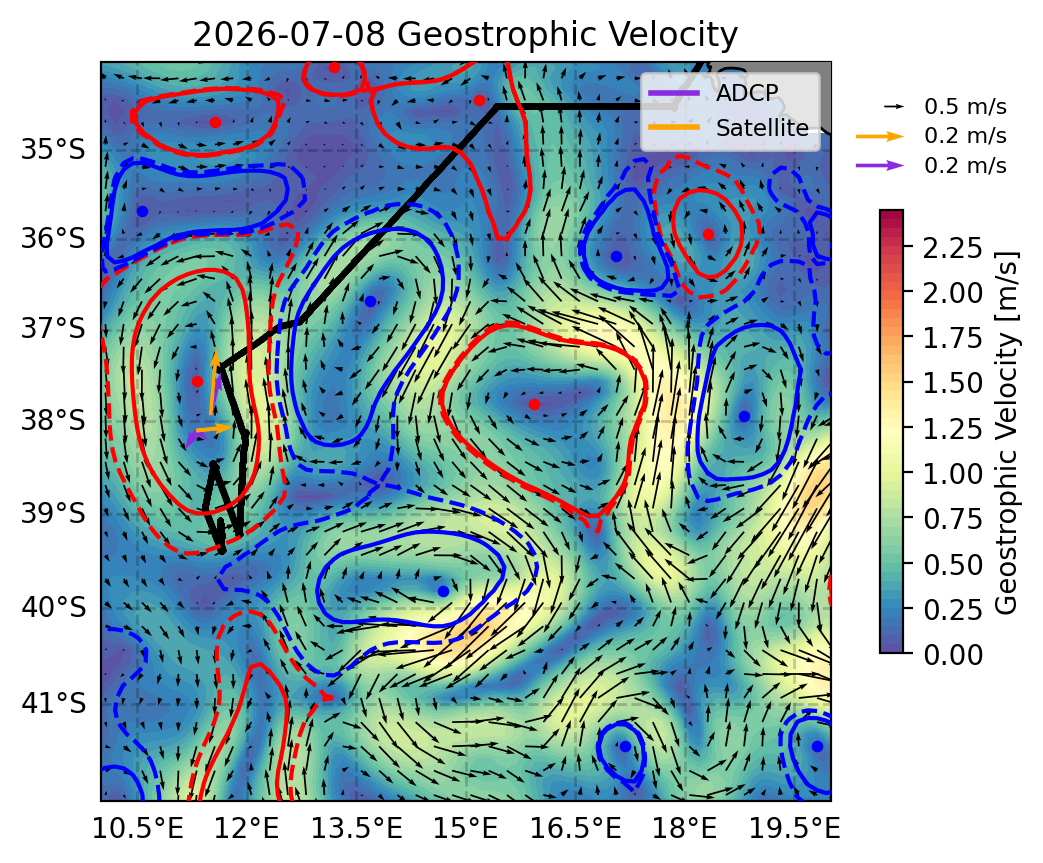

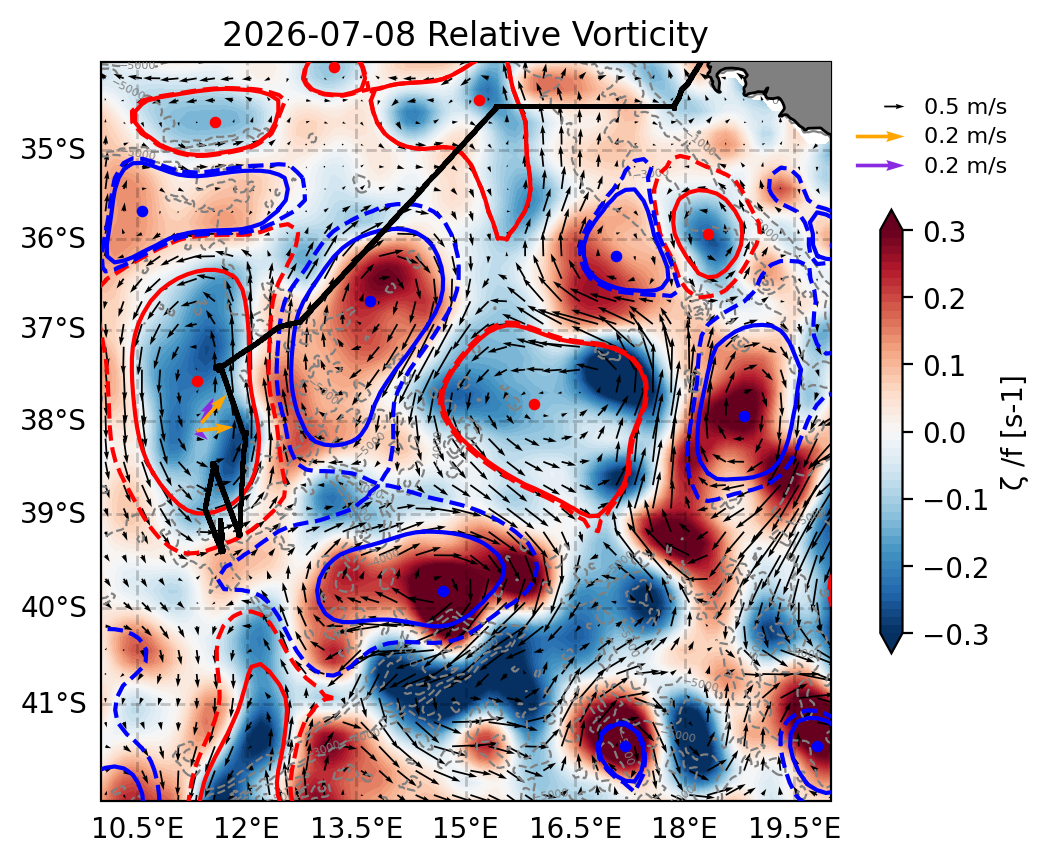

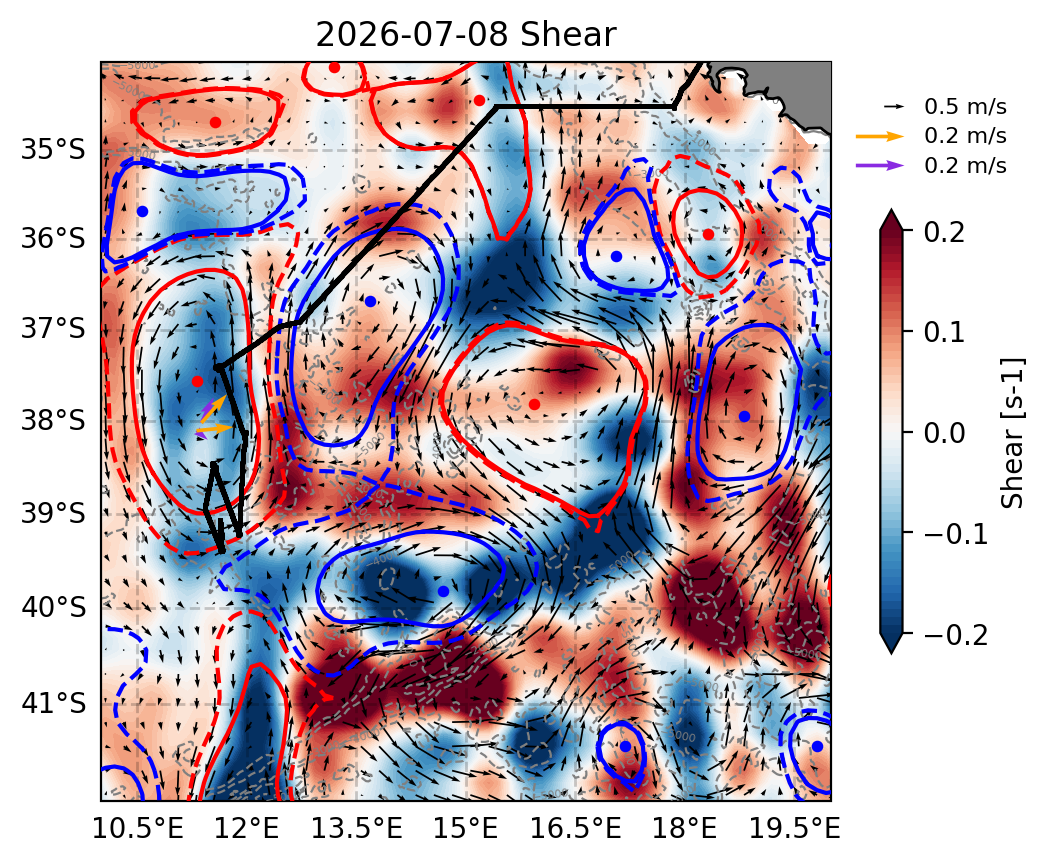

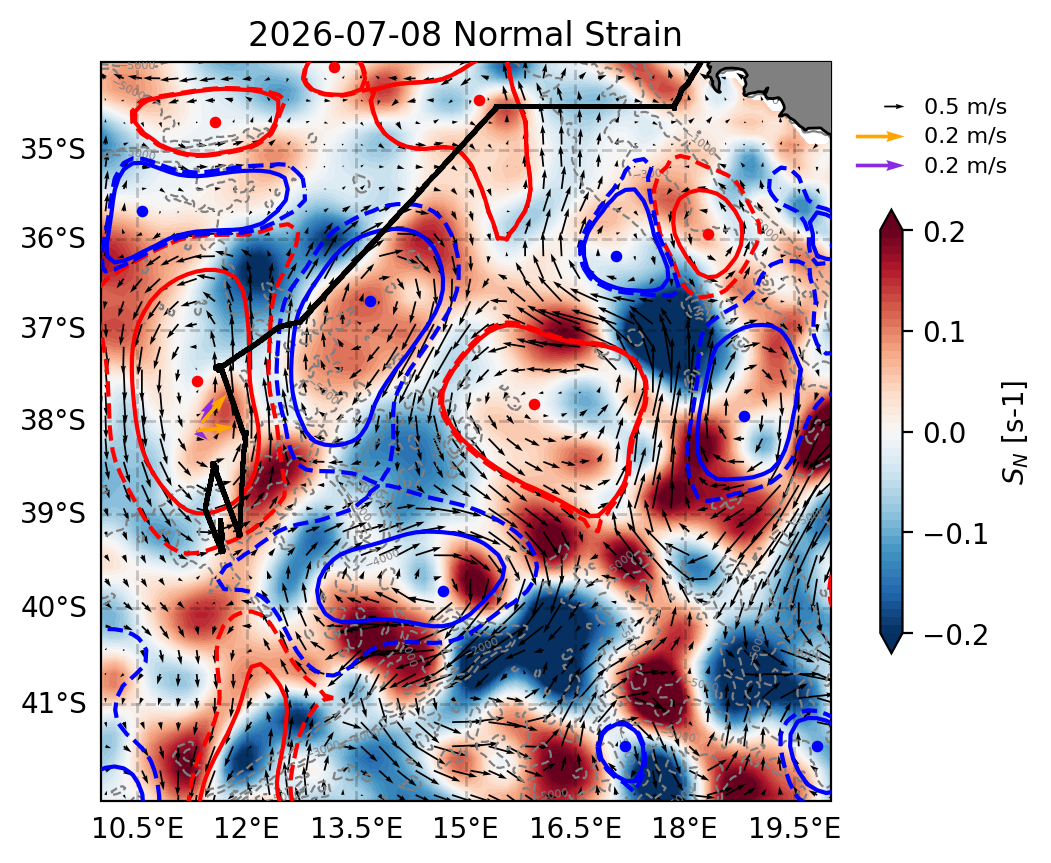

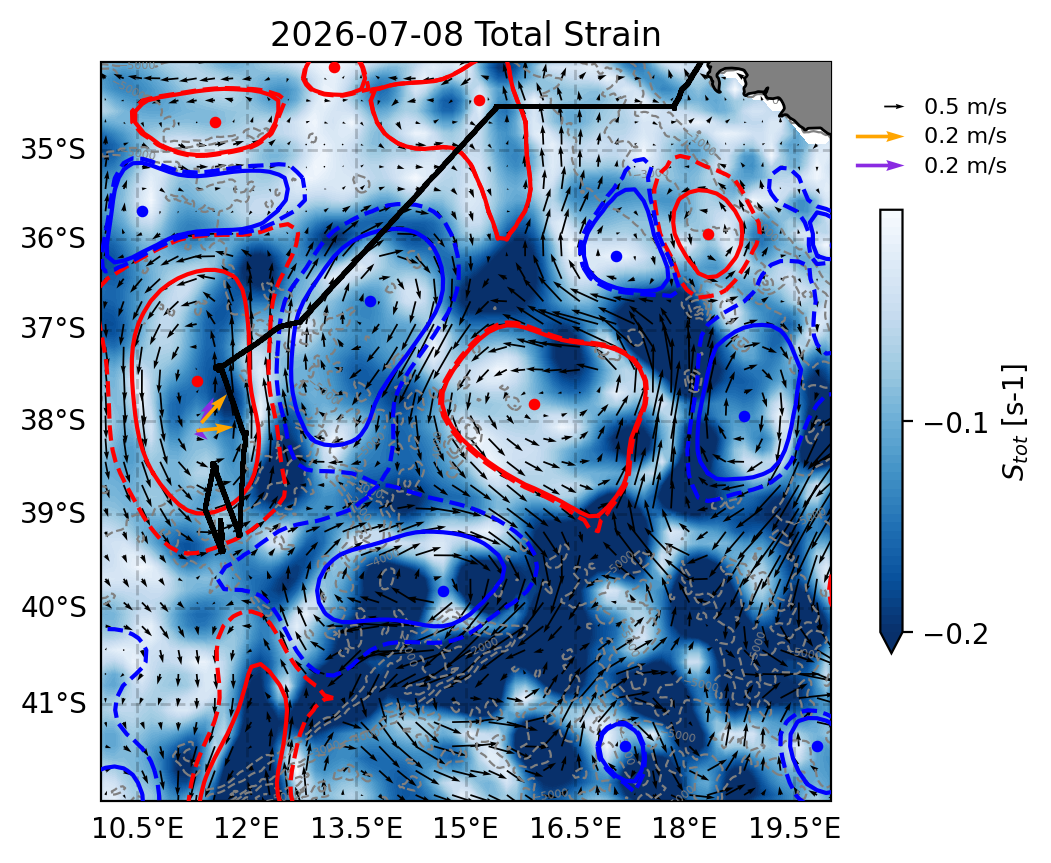

In [ ]:
##### POSITION VARIABLES #####
lon_min, lon_max, lat_min, lat_max = 10, 20, -42, -34
pos_west,pos_east,pos_south,pos_north  = 10, 20, -42,-34  #Reset the area
extent=[pos_west, pos_east, pos_south, pos_north]

vmin_adt = -0.25
vmax_adt = 1.55

curr_time_str = times_str[-1]
dir_eddies = dir + f"Eddies/{curr_time_str}/{curr_time_str}_toeddies/"
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

month, day = times[-1]
file_adt = daily_adt_files[-1]
print(f"Processing {month}-{day} for ADT and {file_adt} for satellite")

sat = load_satellite(adt_daily_dir + file_adt)
sat_mag = velocity_magnitude(sat["ugos"], sat["vgos"])
rel_vort = relative_vorticity_from_uv(sat["ugos"], sat["vgos"], sat["lon"], sat["lat"])
shear = shear_from_uv(sat["ugos"], sat["vgos"], sat["lon"], sat["lat"])
normal_strain  = normal_strain_from_uv(sat["ugos"], sat["vgos"], sat["lon"], sat["lat"])
tot_strain = np.sqrt(normal_strain**2 + shear**2)

adcp_cut = get_time_mask(month, day, new_adcp, new_adcp.time, dm = True)

x_dist = along_track_distance(
    adcp_cut.lon_adcp.values,
    adcp_cut.lat_adcp.values
)

curr_adt = xr.open_dataset(adt_daily_dir + file_adt)
u_adcp, v_adcp = average_adcp_velocity(adcp_cut)
adcp_mag = velocity_magnitude(adcp_cut.uvel_adcp.values, adcp_cut.vvel_adcp.values)
ugos_track, vgos_track = interpolate_satellite(
    adcp_cut,
    sat["ugos"],
    sat["vgos"]
)

avg_curr_mag_adcp = velocity_magnitude(u_adcp, v_adcp)
avg_curr_mag_sat = velocity_magnitude(ugos_track, vgos_track)

plot_adcp_satellite_map_no_xdist(
        adcp_cut,
        sat,
        sat_mag,
        u_adcp,
        v_adcp,
        ugos_track,
        vgos_track,
        anti,
        cyc,
        extent,
        f"{curr_time_str} Geostrophic Velocity",
        proj,
        crs,
        ft,
        longs_bato,
        lat_bato,
    )

plot_rel_vort_map(
    adcp_cut,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    sat,
    rel_vort/f0,
    anti,
    cyc,
    extent,
    f"{curr_time_str} Relative Vorticity",
    proj,
    crs,
    ft,
    -0.3,
    0.3,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    "\u03B6 /f",
    deg=0.25
)

plot_rel_vort_map(
    adcp_cut,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    sat,
    shear/f0,
    anti,
    cyc,
    extent,
    f"{curr_time_str} Shear",
    proj,
    crs,
    ft,
    -0.2,
    0.2,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    "Shear",
    deg=0.25
)
plot_rel_vort_map(
    adcp_cut,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    sat,
    normal_strain/f0,
    anti,
    cyc,
    extent,
    f"{curr_time_str} Normal Strain",
    proj,
    crs,
    ft,
    -0.2,
    0.2,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    r'$S_{N}$',
    deg=0.25
)
plot_rel_vort_map(
    adcp_cut,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    sat,
    np.sqrt(tot_strain**2)/f0,
    anti,
    cyc,
    extent,
    f"{curr_time_str} Total Strain",
    proj,
    crs,
    ft,
    -0.2,
    0,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    r'$S_{tot}$',
    cmap='Blues_r',
    extend=False,
    deg=0.25
)

In [15]:
import os

output_dir = "./Movies"

variables = [
    "velocity",
    "relative_vorticity",
    "shear",
    "normal_strain",
    "total_strain"
]

os.makedirs(output_dir, exist_ok=True)

for t in times_str:
    os.makedirs(os.path.join(output_dir, t), exist_ok=True)

In [18]:
for i, (month, day) in enumerate(times):

    curr_time_str = times_str[i]
    file_adt = daily_adt_files[i]

    print(f"Processing {curr_time_str}")

    ############################
    # Load eddies
    ############################

    dir_eddies = dir + f"Eddies/{curr_time_str}/{curr_time_str}_toeddies/"
    anti, cyc = load_eddies(dir_eddies)

    ############################
    # Satellite
    ############################

    sat = load_satellite(adt_daily_dir + file_adt)

    sat_mag = velocity_magnitude(sat["ugos"], sat["vgos"])

    rel_vort = relative_vorticity_from_uv(
        sat["ugos"],
        sat["vgos"],
        sat["lon"],
        sat["lat"],
    )

    shear = shear_from_uv(
        sat["ugos"],
        sat["vgos"],
        sat["lon"],
        sat["lat"],
    )

    normal_strain = normal_strain_from_uv(
        sat["ugos"],
        sat["vgos"],
        sat["lon"],
        sat["lat"],
    )

    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    ############################
    # ADCP
    ############################

    adcp_cut = get_time_mask(month, day, new_adcp, new_adcp.time, dm = True)

    u_adcp, v_adcp = average_adcp_velocity(adcp_cut)

    ugos_track, vgos_track = interpolate_satellite(
        adcp_cut,
        sat["ugos"],
        sat["vgos"],
    )

    save_dir = os.path.join(output_dir, curr_time_str)
    fig, ax = plot_adcp_satellite_map_no_xdist(
            adcp_cut,
            sat,
            sat_mag,
            u_adcp,
            v_adcp,
            ugos_track,
            vgos_track,
            anti,
            cyc,
            extent,
            f"{curr_time_str} Geostrophic Velocity",
            proj,
            crs,
            ft,
            longs_bato,
            lat_bato,
    )

    fig.savefig(
        os.path.join(save_dir, "velocity.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)

    fig, ax = plot_rel_vort_map(
        adcp_cut,
        u_adcp,
        v_adcp,
        ugos_track,
        vgos_track,
        sat,
        rel_vort/f0,
        anti,
        cyc,
        extent,
        f"{curr_time_str} Relative Vorticity",
        proj,
        crs,
        ft,
        -0.3,
        0.3,
        lon_subset,
        lat_subset,
        depth_subset,
        longs_bato,
        lat_bato,
        r"$\zeta/f$",
        deg=0.25
    )

    fig.savefig(
        os.path.join(save_dir, "relative_vorticity.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)

    fig, ax = plot_rel_vort_map(
        adcp_cut,
        u_adcp,
        v_adcp,
        ugos_track,
        vgos_track,
        sat,
        shear/f0,
        anti,
        cyc,
        extent,
        f"{curr_time_str} Shear",
        proj,
        crs,
        ft,
        -0.2,
        0.2,
        lon_subset,
        lat_subset,
        depth_subset,
        longs_bato,
        lat_bato,
        "Shear",
        deg=0.25
    )

    fig.savefig(
        os.path.join(save_dir, "shear.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)

    fig, ax = plot_rel_vort_map(
        adcp_cut,
        u_adcp,
        v_adcp,
        ugos_track,
        vgos_track,
        sat,
        normal_strain/f0,
        anti,
        cyc,
        extent,
        f"{curr_time_str} Normal Strain",
        proj,
        crs,
        ft,
        -0.2,
        0.2,
        lon_subset,
        lat_subset,
        depth_subset,
        longs_bato,
        lat_bato,
        r"$S_N$",
        deg=0.25
    )

    fig.savefig(
        os.path.join(save_dir, "normal_strain.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)
    fig, ax = plot_rel_vort_map(
        adcp_cut,
        u_adcp,
        v_adcp,
        ugos_track,
        vgos_track,
        sat,
        tot_strain/f0,
        anti,
        cyc,
        extent,
        f"{curr_time_str} Total Strain",
        proj,
        crs,
        ft,
        -0.2,
        0,
        lon_subset,
        lat_subset,
        depth_subset,
        longs_bato,
        lat_bato,
        r"$S_{tot}$",
        cmap="Blues_r",
        extend=False,
        deg=0.25
    )

    fig.savefig(
        os.path.join(save_dir, "total_strain.png"),
        dpi=300,
        bbox_inches="tight",
    )
    plt.close(fig)

Processing 2026-06-29
Processing 2026-06-30
Processing 2026-07-01
Processing 2026-07-02
Processing 2026-07-03
Processing 2026-07-04
Processing 2026-07-05
Processing 2026-07-06
Processing 2026-07-07
Processing 2026-07-08


In [19]:
import imageio.v2 as imageio

movies_dir = os.path.join(output_dir, "movies")
os.makedirs(movies_dir, exist_ok=True)

variables = [
    "velocity",
    "relative_vorticity",
    "shear",
    "normal_strain",
    "total_strain"
]

for var in variables:

    frames = []

    for t in times_str:

        filename = os.path.join(
            output_dir,
            t,
            f"{var}.png"
        )

        frames.append(imageio.imread(filename))

    imageio.mimsave(
        os.path.join(movies_dir, f"{var}.mp4"),
        frames,
        fps=2
    )

    print(f"Saved {var}.mp4")

ValueError: Could not find a backend to open `./Movies/movies/velocity.mp4`` with iomode `wI`.
Based on the extension, the following plugins might add capable backends:
  FFMPEG:  pip install imageio[ffmpeg]
  pyav:  pip install imageio[pyav]

In [20]:
!pip install "imageio[ffmpeg]"

  Using cached imageio_ffmpeg-0.6.0-py3-none-macosx_11_0_arm64.whl.metadata (1.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 315.2 kB/s eta 0:00:0000:0100:03

[notice] A new release of pip is available: 25.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


In [30]:
import imageio.v2 as imageio

print(imageio.help("ffmpeg"))

ImportError: The `FFMPEG` format is not installed. Use `pip install imageio[ffmpeg]` to install it.

In [2]:
# Define (month, day) pairs corresponding to ADCP extraction days
times = [(6, 29), (6, 30), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5)]
times_str = ["2026-06-29", "2026-06-30", "2026-07-01", "2026-07-02", "2026-07-03", "2026-07-04", "2026-07-05"]
vms = [(0, 1.5), (0, 2), (0, 1.5), (0, 1.5), (0, 1), (0, 1), (0, 1)]
extents = [(15, 20, -36, -32), (13, 17.5, -37, -32), (10, 17.5, -39, -32), (10, 14, -40, -36), (10, 14, -39.5, -37), (10, 14, -39.5, -37), (10, 14, -39.5, -37)]
vms_adt = [(-0.1, 0.8), (-0.1, 1.5), (-0.1, 1.5), (-0.1, 1.5), (-0.1, 1.5), (-0.1, 1.5), (-0.1, 1.5)]
comparison = []
# Loop over each day
for i in range(len(times)):
    vmin, vmax = vms[i]
    vmin_adt, vmax_adt = vms_adt[i]
    lon_min, lon_max, lat_min, lat_max = extents[i]
    pos_west,pos_east,pos_south,pos_north  = extents[i]
    extent=[pos_west, pos_east, pos_south, pos_north]
    curr_time_str = times_str[i]
    dir_eddies = dir + f"Eddies/{curr_time_str}/{curr_time_str}_toeddies/"

    files = os.listdir(dir_eddies)
    anti, cyc = load_eddies(dir_eddies)
    month, day = times[i]
    file_adt = daily_adt_files[i]
    print(f"Processing {month}-{day} for ADCP and {file_adt} for satellite")

    sat = load_satellite(adt_daily_dir + file_adt)
    sat_mag = velocity_magnitude(sat["ugos"], sat["vgos"])
    
    curr_day = get_time_mask(month, day, new_adcp, new_adcp.time)

    x_dist = along_track_distance(
        curr_day.lon_adcp.values,
        curr_day.lat_adcp.values
    )

    curr_adt = xr.open_dataset(adt_daily_dir + file_adt)
    u_adcp, v_adcp = average_adcp_velocity(curr_day)
    adcp_mag = velocity_magnitude(curr_day.uvel_adcp.values, curr_day.vvel_adcp.values)
    ugos_track, vgos_track = interpolate_satellite(
        curr_day,
        sat["ugos"],
        sat["vgos"]
    )
    avg_curr_mag_adcp = velocity_magnitude(u_adcp, v_adcp)
    avg_curr_mag_sat = velocity_magnitude(ugos_track, vgos_track)
    
    percent_diff = (
        (avg_curr_mag_sat - avg_curr_mag_adcp) / avg_curr_mag_adcp
    )
    mean_percent_diff = np.nanmean(percent_diff)

    print(f"{curr_time_str}:")
    print(f"Mean magnitude percent difference = {mean_percent_diff:.1f}%")

    # ==========================
    # Percent difference
    # ==========================
    fig, ax = plt.subplots(figsize=(8, 4))
    x = x_dist / 1000
    y = percent_diff * 100

    bin_width = 5

    bins = np.arange(
        np.nanmin(x),
        np.nanmax(x) + bin_width,
        bin_width
    )

    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    digitized = np.digitize(x, bins)

    binned_mean = np.array([
        np.nanmean(y[digitized == i])
        for i in range(1, len(bins))
    ])

    ax.bar(
        bin_centers,
        binned_mean,
        width=bin_width,
        color="tab:blue",
        edgecolor="black",
        linewidth=0.8,
        align="center"
    )

    ax.axhline(
        mean_percent_diff*100,
        color="red",
        ls="--",
        lw=1.5,
        label=f"Mean = {mean_percent_diff*100:.1f}%"
    )

    ax.set_xlabel("Along-track distance (km)")
    ax.set_ylabel("Percent difference (SAT/ADCP) (%)")
    ax.invert_xaxis()
    ax.set_title(f"{curr_time_str}: ADCP vs Satellite mismatch (5 km bins)")
    ax.grid(alpha=0.3)
    ax.legend()

    plt.show()


    # ==========================
    # Direction difference
    # ==========================
    adcp_angle = np.degrees(np.arctan2(v_adcp, u_adcp))

    sat_angle = np.degrees(
        np.arctan2(
            vgos_track.values,
            ugos_track.values
        )
    )

    angle_diff = np.abs(adcp_angle - sat_angle)
    angle_diff = np.where(angle_diff > 180, 360 - angle_diff, angle_diff)

    mean_angle_diff = np.nanmean(angle_diff)

    print(f"Mean angle difference = {mean_angle_diff:.1f}°")

    fig, ax = plt.subplots(figsize=(8, 4))

    x = x_dist / 1000
    y = angle_diff

    bin_width = 5

    bins = np.arange(
        np.nanmin(x),
        np.nanmax(x) + bin_width,
        bin_width
    )

    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    digitized = np.digitize(x, bins)

    binned_mean = np.array([
        np.nanmean(y[digitized == i])
        for i in range(1, len(bins))
    ])

    ax.bar(
        bin_centers,
        binned_mean,
        width=bin_width,
        color="tab:blue",
        edgecolor="black",
        linewidth=0.8,
        align="center"
    )

    ax.axhline(
        mean_angle_diff,
        color="red",
        ls="--",
        lw=1.5,
        label=f"Mean = {mean_angle_diff:.1f}%"
    )
    ax.set_xlabel("Along-track distance (km)")
    ax.set_ylabel("Direction difference (°)")
    ax.set_title(f"{curr_time_str}: ADCP vs Satellite Flow Direction")
    ax.set_ylim(0, 180)
    ax.invert_xaxis()
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()
    
    plot_alongtrack(
        x_dist,
        avg_curr_mag_adcp,
        avg_curr_mag_sat,
        curr_time_str,
    )
    comparison.append({
        "date": curr_time_str,
        "mag_percent_diff": mean_percent_diff,
        "angle_diff_deg": mean_angle_diff,
    })

    plot_adcp_satellite_map(
        curr_day,
        sat,
        sat_mag,
        u_adcp,
        v_adcp,
        ugos_track,
        vgos_track,
        anti,
        cyc,
        extent,
        curr_time_str,
        proj,
        crs,
        ft,
        longs_bato,
        lat_bato,
        x_dist
    )

    plot_adt_map(
        sat,
        anti,
        cyc,
        extent,
        curr_time_str,
        proj,
        crs,
        ft,
        vmin_adt,
        vmax_adt,
        lon_subset,
        lat_subset,
        depth_subset,
        longs_bato,
        lat_bato,
        curr_day,
        x_dist
    )
    curr_day2 = get_time_mask(month, day, new_adcp, new_adcp.time, False)
    adcp_mag2 = velocity_magnitude(curr_day2.uvel_adcp.values, curr_day2.vvel_adcp.values)
    x_dist2 = along_track_distance(
        curr_day2.lon_adcp.values,
        curr_day2.lat_adcp.values
    )
    plot_adcp_section(
        curr_day2,
        adcp_mag2,
        x_dist2 / 1000,
        curr_time_str,
        vmin,
        vmax,
    )

TypeError: unsupported operand type(s) for +: 'builtin_function_or_method' and 'str'

In [57]:
# # Define (month, day) pairs corresponding to ADCP extraction days
# times = [(6, 29), (6, 30), (7, 1), (7, 2)]
# times_str = ["2026-06-29", "2026-06-30", "2026-07-01", "2026-07-02", "2026-07-03"]
# vms = [(0, 1.5), (0, 2), (0, 1.5), (0, 1)]
# extents = [(15, 20, -36, -32), (13, 17.5, -37, -32), (10, 17.5, -39, -32), (10, 14, -39, -36), (10, 14, -39.5, -37)]
# vms_adt = [(-0.1, 0.8), (-0.1, 1.5), (-0.1, 1.5), (-0.1, 1.5), (-0.1, 1.0)]

# # Loop over each day
# for i in range(len(times)):
#     vmin_adt, vmax_adt = vms_adt[i]
#     lon_min, lon_max, lat_min, lat_max = extents[i]
#     pos_west,pos_east,pos_south,pos_north  = extents[i]
#     extent=[pos_west, pos_east, pos_south, pos_north]
#     curr_time_str = times_str[i]
#     dir_eddies = dir + f"Eddies/{curr_time_str}/{curr_time_str}_toeddies/"
#     files = os.listdir(dir_eddies)
#     for fname in files:
#         if "anti" in fname:
#             if "maxspeed" in fname:
#                 gdf_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
#             elif "outcontour" in fname:
#                 gdf_oc = gpd.read_file(dir_eddies + fname)
#             elif "centers" in fname:
#                 gdf_cent = gpd.read_file(dir_eddies + fname)
#             else:
#                 print(f"Error, no file loaded for {fname}")
#         else:
#             if "maxspeed" in fname:
#                 gdfcyc_ms = gpd.read_file(dir_eddies + fname) # 06-29 #7, 13, 14, 30 invalid
#             elif "outcontour" in fname:
#                 gdfcyc_oc = gpd.read_file(dir_eddies + fname)
#             elif "centers" in fname:
#                 gdfcyc_cent = gpd.read_file(dir_eddies + fname)
#             else:
#                 print(f"Error, no file loaded for {fname}")

    
#     # Extract current month/day and corresponding satellite file
#     month, day = times[i]
#     if i == len(times) - 1:
#         i_adt = i - 1
#     else:
#         i_adt = i
#     file_adt = daily_adt_files[i_adt]

#     print(f"Processing {month}-{day} for ADCP and {file_adt} for satellite")

#     # =========================
#     # OPEN DAILY SATELLITE DATA
#     # =========================
#     curr_adt = xr.open_dataset(adt_daily_dir + file_adt)

#     # Drop time variable if it exists (avoids xarray coordinate conflicts)
#     if "time" in curr_adt:
#         curr_adt = curr_adt.drop_vars("time")

#     # Extract satellite variables
#     lats_sat = curr_adt['latitude']
#     lons_sat = curr_adt['longitude']
#     time_sat = curr_adt['time']
#     adt_sat = curr_adt['adt']

#     # Squeeze removes singleton dimensions (e.g., time=1)
#     ugos_sat = np.squeeze(curr_adt['ugos'])
#     vgos_sat = np.squeeze(curr_adt['vgos'])

#     # Compute satellite current speed magnitude on the grid
#     current_mag_sat = np.sqrt(ugos_sat.values**2 + vgos_sat.values**2)

#     # =========================
#     # EXTRACT ADCP DATA FOR DAY
#     # =========================
#     curr_day_adcp = get_time_mask(month, day, new_adcp, new_adcp.time)
#     # =========================
#     # COMPUTE ALONG-TRACK DISTANCE (SHIP TRACK ONLY)
#     # =========================
#     x_dist = along_track_distance(
#         curr_day_adcp.lon_adcp.values,
#         curr_day_adcp.lat_adcp.values
#     )
   
#     # =========================
#     # INTERPOLATE SATELLITE ONTO SHIP TRACK
#     # (project satellite fields onto ADCP positions)
#     # =========================
#     ugos_sat_on_adcp = ugos_sat.interp(
#         longitude=curr_day_adcp.lon_adcp,
#         latitude=curr_day_adcp.lat_adcp,
#         method='nearest'
#     )

#     vgos_sat_on_adcp = vgos_sat.interp(
#         longitude=curr_day_adcp.lon_adcp,
#         latitude=curr_day_adcp.lat_adcp,
#         method='nearest'
#     )

#     # Compute ADCP current magnitude (u, v velocities)
#     adcp_mag = np.sqrt(
#         curr_day_adcp.uvel_adcp.values**2 +
#         curr_day_adcp.vvel_adcp.values**2
#     )

#     # mask only invalid values (not whole rows)
#     adcp_mag_masked = np.where(
#         np.isnan(adcp_mag).any(axis=1),
#         np.nan,
#         np.nanmean(adcp_mag, axis=1)
#     )

#     # Compute satellite current magnitude on ship tracka
#     sat_mag = np.sqrt(
#         ugos_sat_on_adcp.values**2 +
#         vgos_sat_on_adcp.values**2
#     )

#     # =========================
#     # HANDLE NaNs IN ADCP DATA
#     # (remove time steps with missing depth values)
#     # =========================
#     mask = ~np.isnan(adcp_mag).any(axis=1)

#     avg_curr_mag_adcp = np.full(adcp_mag.shape[0], np.nan)
#     avg_curr_mag_adcp[mask] = np.mean(adcp_mag[mask], axis=1)
#     proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)
#     vmin, vmax = vms[i]
#     # # =========================
#     # # PLOT 1: ALONG-TRACK COMPARISON
#     # # =========================
#     plt.figure()
#     plt.plot(-x_dist / 1000, avg_curr_mag_adcp, label="ADCP", color='blueviolet')
#     # plt.plot(curr_day_adcp.time.values, avg_curr_mag_adcp, label="ADCP")
#     plt.plot(-x_dist / 1000, sat_mag, label="Satellite (Geostrophic)", color='orange')

#     plt.legend()
#     plt.xlabel("Along-track distance (km)")
#     plt.ylabel("Velocity")
#     plt.title(f"{month}-{day}: ADCP vs Satellite along-track")
#     plt.show()

#     fig = plt.figure(dpi=200)
#     ax0 = fig.add_subplot(1, 1, 1, projection=proj)

#     ax0.set_extent(extent,crs=ccrs.PlateCarree())
#     ax0.set_title(f'{date}')
#     ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
#     ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
#     map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
#     map_grid.top_labels = False
#     map_grid.left_labels = True
#     map_grid.right_labels = False
#     map_grid.xlabel_style = {'size': ft}
#     map_grid.ylabel_style = {'size': ft}
#     c2 = ax0.contourf(lons_sat, lats_sat, current_mag_sat,  levels=np.arange(0, 2.5, 0.1), cmap='Spectral_r',
#             transform=crs, linestyles='dashed', linewidths=0.7)    
#     ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='black', zorder=90)


#     mask = ~np.isnan(curr_day_adcp.uvel_adcp.values).any(axis=1)
#     u_adcp= np.full(curr_day_adcp.uvel_adcp.values.shape[0], np.nan)
#     u_adcp[mask] = np.mean(curr_day_adcp.uvel_adcp.values[mask], axis=1)

#     mask = ~np.isnan(curr_day_adcp.vvel_adcp.values).any(axis=1)
#     v_adcp= np.full(curr_day_adcp.vvel_adcp.values.shape[0], np.nan)
#     v_adcp[mask] = np.mean(curr_day_adcp.vvel_adcp.values[mask], axis=1)

#     step = 50
#     ax0.quiver(
#         curr_day_adcp.lon_adcp.values[::step],
#         curr_day_adcp.lat_adcp.values[::step],
#         u_adcp[::step],
#         v_adcp[::step],
#         transform=crs,
#         scale=3,              # important change
#         width=0.007,
#         color='blueviolet',
#         alpha=1.0,
#         zorder=100)


#     mask = ~np.isnan(curr_day_adcp.uvel_adcp.values).any(axis=1)
#     u_adcp= np.full(curr_day_adcp.uvel_adcp.values.shape[0], np.nan)
#     u_adcp[mask] = np.mean(curr_day_adcp.uvel_adcp.values[mask], axis=1)

#     mask = ~np.isnan(curr_day_adcp.vvel_adcp.values).any(axis=1)
#     v_adcp= np.full(curr_day_adcp.vvel_adcp.values.shape[0], np.nan)
#     v_adcp[mask] = np.mean(curr_day_adcp.vvel_adcp.values[mask], axis=1)

#     ax0.quiver(
#         curr_day_adcp.lon_adcp.values[::step],
#         curr_day_adcp.lat_adcp.values[::step],
#         ugos_sat_on_adcp.values[::step],
#         vgos_sat_on_adcp.values[::step],
#         transform=crs,
#         scale=3,              # important change    # makes arrows in data units
#         width=0.007,
#         color='orange',
#         alpha=1.0,
#         zorder=100
#     )
#     for i in range(len(gdf_cent)):
#         if gdf_ms['geometry'][i] is not None:
#             x,y = gdf_ms['geometry'][i].exterior.xy
#             ax0.plot(x, y, zorder=10, color='red', transform=crs)
#             xs,ys = gdf_oc['geometry'][i].exterior.xy
#             ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
#             x_c = gdf_cent['geometry'][i].x
#             y_c = gdf_cent['geometry'][i].y
#             ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

#     for i in range(len(gdfcyc_cent)):
#         if gdfcyc_ms['geometry'][i] is not None:
#             x,y = gdfcyc_ms['geometry'][i].exterior.xy
#             ax0.plot(x, y, zorder=10, color='blue', transform=crs)
#             xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
#             ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
#             x_c = gdfcyc_cent['geometry'][i].x
#             y_c = gdfcyc_cent['geometry'][i].y
#             ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
#     cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
#     cbar.ax.tick_params(labelsize=10)
#     cbar.set_ticks(np.arange(0, 2.5, 0.2))
#     cbar.set_label('Geostrophic Velocity [m/s]', fontsize=10, labelpad=10)
#     cbar.outline.set_linewidth(1)
#     plt.title(f"2026-{month}-{day}")
#     plt.show()
#     plt.savefig(save_fig + f"{curr_time_str}_adcp_sat.png")

#     fig = plt.figure(dpi=200)

#     ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
#     ax0.set_title(f'{curr_time_str}')
#     ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
#     ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
#     ax0.set_extent(extent)
#     map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
#     map_grid.top_labels = False
#     map_grid.left_labels = True
#     map_grid.right_labels = False
#     map_grid.xlabel_style = {'size': ft}
#     map_grid.ylabel_style = {'size': ft}

#     # Plot bathymetric relief
#     bathy_contours = np.arange(-5500, 0, 700)
#     c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
#     ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

#     # ADT contours
#     c_adt = ax0.contourf(lons_sat, lats_sat, adt_sat[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
#                 transform=crs, linestyles='dashed', linewidths=0.7, zorder=2)
#     lon_2D, lat_2D = np.meshgrid(lons_sat.values, lats_sat.values)
#     step = 2
#     Q = ax0.quiver(
#         lon_2D[::step, ::step],
#         lat_2D[::step, ::step],
#         ugos_sat.values[::step, ::step],
#         vgos_sat.values[::step, ::step],
#         transform=crs,
#         scale=18, zorder=8)
#     # ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
#     #             transform=crs, linestyles='solid', linewidths=0.7)

#     cbar_adt = fig.colorbar(c_adt, ax=ax0, shrink=0.6)
#     cbar_adt.ax.tick_params(labelsize=10)
#     cbar_adt.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
#     cbar_adt.set_label('ADT [m]', fontsize=10, labelpad=10)
#     cbar_adt.outline.set_linewidth(1)

#     for i in range(len(gdf_cent)):
#         if gdf_ms['geometry'][i] is not None:
#             x,y = gdf_ms['geometry'][i].exterior.xy
#             ax0.plot(x, y, zorder=10, color='red', transform=crs)
#             xs,ys = gdf_oc['geometry'][i].exterior.xy
#             ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
#             x_c = gdf_cent['geometry'][i].x
#             y_c = gdf_cent['geometry'][i].y
#             ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

#     for i in range(len(gdfcyc_cent)):
#         if gdfcyc_ms['geometry'][i] is not None:
#             x,y = gdfcyc_ms['geometry'][i].exterior.xy
#             ax0.plot(x, y, zorder=10, color='blue', transform=crs)
#             xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
#             ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
#             x_c = gdfcyc_cent['geometry'][i].x
#             y_c = gdfcyc_cent['geometry'][i].y
#             ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
#     arrow_handle = FancyArrowPatch(
#         (0, 0), (1, 0),
#         arrowstyle='->',
#         mutation_scale=10,
#         color='k'
#     )
#     ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
#     ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

#     leg = plt.legend(fontsize='x-small', loc = 'upper right')
#     leg.set_zorder(100) 


#     # =========================
#     # PLOT 2: DEPTH SECTION (ADCP ONLY)
#     # =========================
#     plt.figure()
#     c = plt.contourf(
#         curr_day_adcp.time.values,
#         curr_day_adcp.depth.values,
#         adcp_mag.T, levels=np.arange(vmin, vmax, 0.01)
#     )
#     plt.colorbar(c)
#     plt.xlabel("Time")
#     plt.ylabel("Depth")
#     plt.title("ADCP velocity magnitude (depth-time section)")
#     plt.show()


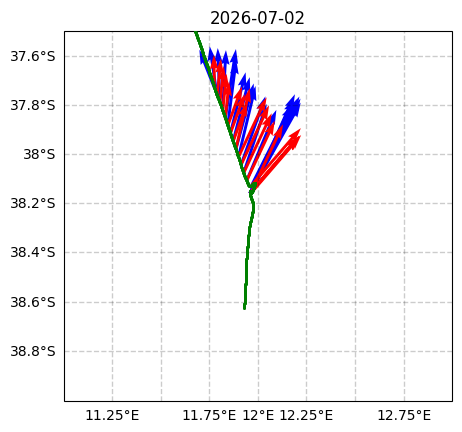

In [ ]:
# proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

# fig = plt.figure(dpi=100)
# ax0 = fig.add_subplot(1, 1, 1, projection=proj)

# ax0.set_extent([11, 13, -39, -37.5],
#                crs=ccrs.PlateCarree())
# ax0.set_title(f'{date}')
# ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
# ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
# map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
# map_grid.top_labels = False
# map_grid.left_labels = True
# map_grid.right_labels = False
# map_grid.xlabel_style = {'size': ft}
# map_grid.ylabel_style = {'size': ft}
# ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)


# mask = ~np.isnan(curr_day_adcp.uvel_adcp.values).any(axis=1)
# u_adcp= np.full(curr_day_adcp.uvel_adcp.values.shape[0], np.nan)
# u_adcp[mask] = np.mean(curr_day_adcp.uvel_adcp.values[mask], axis=1)

# mask = ~np.isnan(curr_day_adcp.vvel_adcp.values).any(axis=1)
# v_adcp= np.full(curr_day_adcp.vvel_adcp.values.shape[0], np.nan)
# v_adcp[mask] = np.mean(curr_day_adcp.vvel_adcp.values[mask], axis=1)

# step = 10
# ax0.quiver(
#     curr_day_adcp.lon_adcp.values[::step],
#     curr_day_adcp.lat_adcp.values[::step],
#     u_adcp[::step],
#     v_adcp[::step],
#     transform=crs,
#     scale=2.5,
#     color='blue')


# mask = ~np.isnan(curr_day_adcp.uvel_adcp.values).any(axis=1)
# u_adcp= np.full(curr_day_adcp.uvel_adcp.values.shape[0], np.nan)
# u_adcp[mask] = np.mean(curr_day_adcp.uvel_adcp.values[mask], axis=1)

# mask = ~np.isnan(curr_day_adcp.vvel_adcp.values).any(axis=1)
# v_adcp= np.full(curr_day_adcp.vvel_adcp.values.shape[0], np.nan)
# v_adcp[mask] = np.mean(curr_day_adcp.vvel_adcp.values[mask], axis=1)

# step = 10
# ax0.quiver(
#     curr_day_adcp.lon_adcp.values[::step],
#     curr_day_adcp.lat_adcp.values[::step],
#     ugos_sat_on_adcp[::step],
#     vgos_sat_on_adcp[::step],
#     transform=crs,
#     scale=2.5,
#     color='red')

# # cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
# # cbar.ax.tick_params(labelsize=10)
# # cbar.set_ticks(np.arange(0, 2.0, 0.2))
# # cbar.set_label('Geostrophic Velocity [m/s]', fontsize=10, labelpad=10)
# # cbar.outline.set_linewidth(1)

In [59]:
# import matplotlib.lines as mlines
# from matplotlib.patches import FancyArrowPatch
# fig = plt.figure(dpi=300)

# ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
# ax0.set_title(f'{date}')
# ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
# ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
# ax0.set_extent(extent)
# map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
# map_grid.top_labels = False
# map_grid.left_labels = True
# map_grid.right_labels = False
# map_grid.xlabel_style = {'size': ft}
# map_grid.ylabel_style = {'size': ft}

# # Plot bathymetric relief
# bathy_contours = np.arange(-5500, 0, 700)
# c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
# ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# # ADT contours
# c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
#             transform=crs, linestyles='dashed', linewidths=0.7, zorder=2)
# lon_2D, lat_2D = np.meshgrid(lons, lats)
# step = 2
# Q = ax0.quiver(
#     lon_2D[::step, ::step],
#     lat_2D[::step, ::step],
#     ugos[::step, ::step],
#     vgos[::step, ::step],
#     transform=crs,
#     scale=18, zorder=8)
# # ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
# #             transform=crs, linestyles='solid', linewidths=0.7)

# cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
# cbar.ax.tick_params(labelsize=10)
# cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
# cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
# cbar.outline.set_linewidth(1)

# for i in range(len(gdf_cent)):
#     if gdf_ms['geometry'][i] is not None:
#         x,y = gdf_ms['geometry'][i].exterior.xy
#         ax0.plot(x, y, zorder=10, color='red', transform=crs)
#         xs,ys = gdf_oc['geometry'][i].exterior.xy
#         ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
#         x_c = gdf_cent['geometry'][i].x
#         y_c = gdf_cent['geometry'][i].y
#         ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

# for i in range(len(gdfcyc_cent)):
#     if gdfcyc_ms['geometry'][i] is not None:
#         x,y = gdfcyc_ms['geometry'][i].exterior.xy
#         ax0.plot(x, y, zorder=10, color='blue', transform=crs)
#         xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
#         ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
#         x_c = gdfcyc_cent['geometry'][i].x
#         y_c = gdfcyc_cent['geometry'][i].y
#         ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)
# ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")

# h, m = format_time(times[0])
# upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s1_x, s1_y, s=20, color='orange', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}")

# ax0.annotate(
#         "S6",
#         xy=(s1_x, s1_y),
#         xycoords=crs,
#         xytext=(5, -3),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='orange',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
# h, m = format_time(times[1])
# upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s2_x, s2_y, s=20, color='lime', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}")
# ax0.annotate(
#         "S7",
#         xy=(s2_x, s2_y),
#         xycoords=crs,
#         xytext=(-4, 5),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='lime',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
# h, m = format_time(times[2])
# upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s3_x, s3_y, s=20, color='indigo', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}0")
# ax0.annotate(
#         "S8",
#         xy=(s3_x, s3_y),
#         xycoords=crs,
#         xytext=(-14, -4.5),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='indigo',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
# ax0.annotate(
#     '',
#     xy=(s1_x, s1_y), xytext=(ship_x, ship_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='orange', lw=2),
#     zorder=19
# )
# # Arrow from Cast 1 to Cast 2
# ax0.annotate(
#     '',
#     xy=(s2_x, s2_y), xytext=(s1_x, s1_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='lime', lw=2),
#     zorder=19
# )

# # Arrow from Cast 2 to Cast 3
# ax0.annotate(
#     '',
#     xy=(s3_x, s3_y), xytext=(s2_x, s2_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='indigo', lw=2),
#     zorder=19
# )
# # ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
# arrow_handle = FancyArrowPatch(
#     (0, 0), (1, 0),
#     arrowstyle='->',
#     mutation_scale=10,
#     color='k'
# )
# ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
# ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

# leg = plt.legend(fontsize='x-small', loc = 'upper right')
# leg.set_zorder(100) 
# plt.savefig(save_fig + f"{date}_adt_{title}.png")

In [58]:
# proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

# fig = plt.figure(dpi=300)
# ax0 = fig.add_subplot(1, 1, 1, projection=proj)

# ax0.set_extent([lon_min, lon_max, lat_min, lat_max],
#                crs=ccrs.PlateCarree())
# ax0.set_title(f'{date}')
# ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
# ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
# ax0.set_extent(extent)
# map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
# map_grid.top_labels = False
# map_grid.left_labels = True
# map_grid.right_labels = False
# map_grid.xlabel_style = {'size': ft}
# map_grid.ylabel_style = {'size': ft}

# # Plot bathymetric relief
# # bathy_contours = np.arange(-5500, 0, 700)
# # c = ax0.contour(lon_subset, lat_subset, depth_subset, levels = len(bathy_contours), colors="grey", linestyles='solid', transform=crs, linewidths=0.8, zorder=5)
# # ax0.clabel(c, inline=True, fontsize=4, fmt='%1.1f')

# # ADT contours
# lon2d, lat2d = np.meshgrid(lons_sst, lats_sst)
# c2 = ax0.pcolormesh(lon2d, lat2d, sst[0,:,:], vmin=13, vmax=20, cmap=cmocean.cm.thermal,
#             transform=crs, linestyles='dashed', linewidths=0.7)

# # ax0.contour(lons, lats, adt,  levels=np.arange(-0.20, 1.15, 0.1), colors='grey',
# #             transform=crs, linestyles='solid', linewidths=0.7)
# lon_2D, lat_2D = np.meshgrid(lons, lats)
# step = 2
# Q = ax0.quiver(
#     lon_2D[::step, ::step],
#     lat_2D[::step, ::step],
#     ugos[::step, ::step],
#     vgos[::step, ::step],
#     transform=crs,
#     scale=18, zorder=8)
# cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
# cbar.ax.tick_params(labelsize=10)
# cbar.set_ticks(np.arange(13, 20, 1))
# cbar.set_label('Temperature [C]', fontsize=10, labelpad=10)
# cbar.outline.set_linewidth(1)

# for i in range(len(gdf_cent)):
#     if gdf_ms['geometry'][i] is not None:
#         x,y = gdf_ms['geometry'][i].exterior.xy
#         ax0.plot(x, y, zorder=10, color='red', transform=crs)
#         xs,ys = gdf_oc['geometry'][i].exterior.xy
#         ax0.plot(xs, ys, zorder=10, color='red', linestyle='--',transform=crs)
#         x_c = gdf_cent['geometry'][i].x
#         y_c = gdf_cent['geometry'][i].y
#         ax0.scatter(x_c, y_c, zorder=10, s=10, color='red',transform=crs)

# for i in range(len(gdfcyc_cent)):
#     if gdfcyc_ms['geometry'][i] is not None:
#         x,y = gdfcyc_ms['geometry'][i].exterior.xy
#         ax0.plot(x, y, zorder=10, color='blue', transform=crs)
#         xs,ys = gdfcyc_oc['geometry'][i].exterior.xy
#         ax0.plot(xs, ys, zorder=10, color='blue', linestyle='--',transform=crs)
#         x_c = gdfcyc_cent['geometry'][i].x
#         y_c = gdfcyc_cent['geometry'][i].y
#         ax0.scatter(x_c, y_c, zorder=10, s=10, color='blue',transform=crs)

# ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")

# h, m = format_time(times[0])
# upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s1_x, s1_y, s=20, color='orange', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}")

# ax0.annotate(
#         "S6",
#         xy=(s1_x, s1_y),
#         xycoords=crs,
#         xytext=(5, -3),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='orange',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
# h, m = format_time(times[1])
# upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s2_x, s2_y, s=20, color='lime', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}")
# ax0.annotate(
#         "S7",
#         xy=(s2_x, s2_y),
#         xycoords=crs,
#         xytext=(-4, 5),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='lime',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
# h, m = format_time(times[2])
# upd_t = curr_t + timedelta(hours=h, minutes=m)
# ax0.scatter(s3_x, s3_y, s=20, color='indigo', zorder=20, transform=crs,
#             label=f"ETA: July-{upd_t.day} {upd_t.hour}:{upd_t.minute}0")
# ax0.annotate(
#         "S8",
#         xy=(s3_x, s3_y),
#         xycoords=crs,
#         xytext=(-14, -4.5),  # <-- offset in points (RIGHT, UP)
#         textcoords='offset points',
#         fontsize='x-small',
#         color='indigo',
#         ha='left',
#         va='bottom',
#         zorder=101,
#         bbox=dict(
#             boxstyle="round,pad=0.2",
#             facecolor="white",
#             edgecolor="black",
#             linewidth=0.5,
#             alpha=0.8
#         )
#     )
# ax0.annotate(
#     '',
#     xy=(s1_x, s1_y), xytext=(ship_x, ship_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='orange', lw=2),
#     zorder=19
# )
# # Arrow from Cast 1 to Cast 2
# ax0.annotate(
#     '',
#     xy=(s2_x, s2_y), xytext=(s1_x, s1_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='lime', lw=2),
#     zorder=19
# )

# # Arrow from Cast 2 to Cast 3
# ax0.annotate(
#     '',
#     xy=(s3_x, s3_y), xytext=(s2_x, s2_y),
#     xycoords=crs._as_mpl_transform(ax0),
#     textcoords=crs._as_mpl_transform(ax0),
#     arrowprops=dict(arrowstyle='->', color='indigo', lw=2),
#     zorder=19
# )
# # ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
# arrow_handle = FancyArrowPatch(
#     (0, 0), (1, 0),
#     arrowstyle='->',
#     mutation_scale=10,
#     color='k'
# )
# # ax0.plot(adcp_lons[::5], adcp_lats[::5], transform=crs, label="ADCP Track", color='black')
# arrow_handle = FancyArrowPatch(
#     (0, 0), (1, 0),
#     arrowstyle='->',
#     mutation_scale=10,
#     color='k'
# )
# ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)
# ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')

# leg = plt.legend(fontsize='x-small', loc = 'upper right')
# leg.set_zorder(100) 
# leg.set_zorder(100) 
# plt.savefig(save_fig + f"{date}_sst_{title}.png")